# Multimodal Music Analysis

The target of this project is the implementation of a complete pipeline for extracting knowledge from music data by combining two different modalities: **Audio** and **Text**. The project is split into two parts:  
1. Preprocessing of the data, generation of embeddings and researching analysis.
2. Classification, Fusion and Evaluation.  
  
This notebook contains the implementation of part 1.


Requirements:

In [ ]:
%pip install seaborn
%pip install datasets
%pip install matplotlib
%pip install vaderSentiment
%pip install kneed
%pip install contractions
%pip install pyspellchecker
%pip install scikit-learn
%pip install pandas
%pip install wordcloud
%pip install tensorflow
%pip install gensim

## **Introduction**  

Firstly, we focus on preprocessing our data and create one final dataframe to work on. We keep a subset of the total songs with the necessary columns to complete our research.  
- We keep songs that belong to the following genres:  
`"latin", "classical", "metal", "jazz", "rap"`  
having in mind the difference and the fame of these genres.  

- We keep all the songs that belong to multiple genres, so we introduce a new column in our dataframe `main_genre` to express the main genre of each song

- We extract the lyrics of each song after parsing the text files (form of the files: `{song_id}.txt`)

- We collect the MFCC stats for each song and we store them as vectors (1x104) for each song in our dataframe.

After, we extract audio and text embeddings from our MFCC stats in order to reduce the dimensionality of the vectors we will work on later. We follow this steps:  

- Extracting audio embeddings from the MFCC stats using Autoencoder and PCA.

- Extraction text embeddings from the lyrics of the song using the `Word2Vec` model from gensim.

In the last part, we visualise and analyse our researching results.

## 1. Data Collection


In [5]:
import pandas as pd
import os

import numpy as np
import tensorflow as tf
import sklearn

import matplotlib.pyplot as plt

- Run the code in the next sections for pre-processing the data 
- In case the file already exists, the next sections are skipped automatically

In [37]:
def filter_by_genres(df, genres_list):
    df['main_genre'] = df['genres'].apply(
        lambda x: str(x).split(",")[0].strip()
    )
    return df[df["main_genre"].isin(genres_list)]

In [38]:
def create_lyrics_df(target_ids, path='data/processed_lyrics'):
    # --- Filtering the lyrics of the songs ---
    lyrics_folder = path

    lyrics_data = []

    for filename in os.listdir(lyrics_folder):
        if filename.endswith('.txt'):
            song_id = filename.replace('.txt', '')
            
            if song_id in target_ids:
                file_path = os.path.join(lyrics_folder, filename)
                
                with open(file_path, 'r', encoding='utf-8') as f:
                    lyrics_text = f.read()
                
                lyrics_data.append({
                    'id': song_id,
                    'lyrics': lyrics_text
                })

    lyrics_df = pd.DataFrame(lyrics_data)
    return lyrics_df

In [39]:
def merge_dataframes(dfs, merge_on):
    merged_df = dfs[0]

    for df in dfs[1:]:
        merged_df = pd.merge(merged_df, df, on=merge_on)

    return merged_df


In [87]:

def collect_data():
    # --- Importing the datasets ---
    genres_df = pd.read_csv('data/id_genres.csv', sep='\t') 
    information_df = pd.read_csv('data/id_information.csv', sep='\t')
    tags_df = pd.read_csv('data/id_tags.csv', sep='\t')
    mfcc_stats_df = pd.read_csv('data/id_mfcc_stats.tsv', sep='\t').dropna()

    # ---- Group mfcc stats in one column for better data ----
    mfcc_stats_df = mfcc_stats_df.copy()

    mfcc_columns = [col for col in mfcc_stats_df.columns if 'mfcc' in col.lower() or 'cov' in col.lower()]

    mfcc_stats_df['audio_stats'] = mfcc_stats_df[mfcc_columns].values.tolist()

    audio_stats_df = mfcc_stats_df.drop(columns=mfcc_columns)

    # --- Filtering the genres dataset to only include the top n most common genres ---
    genres_list = ["latin", "classical", "metal", "jazz", "rap"]
    filtered_genres_df = filter_by_genres(genres_df, genres_list)

    # --- Create dataframe with the lyrics of the songs ---
    lyrics_df = create_lyrics_df(target_ids=set(filtered_genres_df['id'].astype(str)))

    # --- Merging dataframes ---
    dataframes = [filtered_genres_df, information_df, tags_df, audio_stats_df, lyrics_df]
    df = merge_dataframes(dataframes, "id")

    # --- Handling missing and duplicate values ---
    df = df[df['lyrics'].notna()]
    df = df[df['lyrics'].str.strip() != '']
    df = df[df['genres'].notna()]
    df = df[df['genres'].str.strip() != '']
    df = df.drop_duplicates(subset='id', keep='first')

    return df
    

In [123]:
final_df_path = "data/final_data.pkl"
if (os.path.isfile(path=final_df_path)):
    data = pd.read_pickle(final_df_path,)
else:
    data = collect_data()
    data = data.drop(columns=["artist", "album_name"])
    data.to_pickle(final_df_path)
    

data.head()

,id,genres,main_genre,song,tags,audio_stats,lyrics
0,01gyRHLquwXDlhkO,rap,rap,Somebody's Gotta Die,"rap,hip-hop,gangsta rap,east coast rap","[22.731481552124023, -12.233457565307615, 2.38...",sittin crib dreamin leer jet coup way salt sho...
1,01zNMO11qGa7tLqa,rap,rap,Duro Igual Concreto,"rap,brasil","[23.98007202148437, -13.340648651123049, 9.021...",come like readi accept propos without think en...
2,023KeDV5DfyxOplZ,"latin,world",latin,Coincidir,"spanish,fusion,latin,world,mestizo","[23.00562858581543, -5.146606922149658, 5.9469...",love stori never end hide behind corner danc o...
3,03QgQw5LI8x5RTQK,"rap,hip hop",rap,Let's Go (The Royal We),"hip-hop,rap,underground hip-hop,hip hop","[24.5290584564209, -6.960131645202638, -11.235...",let -pron- go anarchist put flame tire walk ar...
5,04Q618WBtwDztix8,"rap,hip hop",rap,Don't Wait - Acoustic,"swedish,rap,hip-hop,hip hop,indie,female vocal...","[23.741424560546875, 10.547664642333984, -22.7...",old friend inde come build come share light ma...


## 2. Feature Extraction

### **Audio Embeddings**

### Autoencoder
Creating and training a simple Autoencoder to compress the vector of the audio embedding to a vector with fewer dimensions.

In [91]:
class Autoencoder(tf.keras.Model):
    def __init__(self, input_dim, encoding_dim=32):
        super(Autoencoder, self).__init__()

        layers = tf.keras.layers

        self.encoder = tf.keras.Sequential([
            layers.Input(shape=(input_dim,)),
            layers.Dense(64, activation='relu'),
            layers.BatchNormalization(),
            layers.Dropout(0.2),
            layers.Dense(encoding_dim, activation='relu')
        ])

        self.decoder = tf.keras.Sequential([
            layers.Input(shape=(encoding_dim,)),
            layers.Dense(64, activation='relu'),
            layers.BatchNormalization(),
            layers.Dropout(0.2),
            layers.Dense(input_dim, activation='linear')
        ])

    def call(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

In [92]:
from sklearn.preprocessing import StandardScaler
from keras.callbacks import EarlyStopping, TensorBoard


'''
Function to train the autoencoder.
Arguments:  - scaled audio_stats from the dataframe ready for training
            - optional: hyperparameters for the training
Returns:    - training history for visualization
            - the trained autoencoder
'''
def autoencoder_training(audio_stats, encoding_dim=32, optimizer="adam", loss="mse",
                         epochs=100, batch_size=32, early_stopping_epoch=20):

    input_dim = audio_stats.shape[1]

    # --- autoencoder ---
    autoencoder = Autoencoder(input_dim, encoding_dim)

    autoencoder.compile(optimizer=optimizer, loss=loss)

    # --- autoencoder training ---
    early_stopping = EarlyStopping(
        monitor='val_loss',
        patience=early_stopping_epoch,
        restore_best_weights=True
    )

    training = autoencoder.fit(audio_stats, audio_stats,
                        epochs=epochs,
                        batch_size=batch_size,
                        shuffle=True,
                        callbacks=[early_stopping],
                        validation_split=0.2)

    return training, autoencoder    


In [93]:
# --- Extraction the audio embeddings from the audio stats column ---
audio_embeddings = np.array(data["audio_stats"].to_list(), dtype=float)
scaler = StandardScaler()
audio_embed_train = scaler.fit_transform(audio_embeddings)

training, autoencoder = autoencoder_training(audio_stats=audio_embed_train)



Epoch 1/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.7941 - val_loss: 0.6784
Epoch 2/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.6074 - val_loss: 0.5760
Epoch 3/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.5217 - val_loss: 0.5058
Epoch 4/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4673 - val_loss: 0.4689
Epoch 5/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4340 - val_loss: 0.4432
Epoch 6/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4104 - val_loss: 0.4260
Epoch 7/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3913 - val_loss: 0.4092
Epoch 8/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3763 - val_loss: 0.3948
Epoch 9/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3639 - val_loss: 0.3879
Epoch 10/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3533 - val_loss: 0.3774
Epoch 11/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3441 - val_loss: 0.3680
Epoch 12/100
143/143 ━━━━━━━━━━━━━━━━━━━━

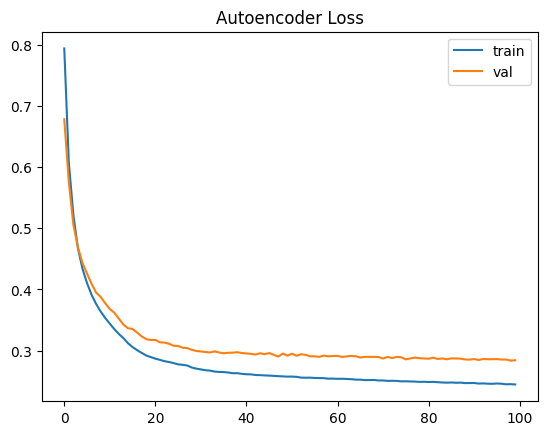

In [94]:
plt.plot(training.history['loss'], label='train')
plt.plot(training.history['val_loss'], label='val')
plt.legend()
plt.title("Autoencoder Loss")
plt.show()

In [95]:
# --- final compresses audio embeddings with 32 dim ---

autoenc_audio_embeddings = autoencoder.encoder.predict(audio_embed_train)
print(autoenc_audio_embeddings.shape)

179/179 ━━━━━━━━━━━━━━━━━━━━ 0s 633us/step
(5717, 32)


### Principal Component Analysis (PCA)

In [96]:
from sklearn.decomposition import PCA

audio_embeddings = np.array(data["audio_stats"].tolist(), dtype=float)
scaler = StandardScaler()
audio_scaled = scaler.fit_transform(audio_embeddings)


pca = PCA(n_components=0.95)  # keep 95% variance
pca_audio_embeddings = pca.fit_transform(audio_scaled)

pca_audio_embeddings.shape

(5717, 77)

In the next section, we compare the difference between PCA and Autoencoder audio embeddings, as well as the text embeddings to the audio embeddings.   

### **Text Embeddings**

In [97]:
import re
import numpy as np
from gensim.models import Word2Vec

#Προεπεξεργασία Lyrics

def preprocess_lyrics(text):
    if not isinstance(text, str):
        return []
    #Αφαίρεση περιεχομένου σε αγκύλες π.χ. [Chorus]
    text = re.sub(r'\[.*?\]', '', text)
    #Μετατροπή σε πεζά (για να αναγνωρίζουμε ίδιες λέξεις)
    text = text.lower()
    #Κρατάμε μόνο γράμματα και αποστροφές, όλα τα άλλα τα πετάμε πχ. αριθμούς
    text = re.sub(r"[^a-z\s']", '', text)
    #Βγάζουμε τα tokens τώρα αλλά όχι τις λέξεις με 2 ή λιγότερα γράμματα (είναι άχρηστες)
    tokens = [t for t in text.split() if len(t) >= 2]
    return tokens

#Εφαρμογή
print("Προεπεξεργασία lyrics...")
data['lyrics_tokens'] = data['lyrics'].apply(preprocess_lyrics)

#Παράδειγμα για να ελέγξουμε ότι το κάναμε σωστά
print(f"Παράδειγμα tokens:\n{data['lyrics_tokens'].iloc[32][:15]}")
print(f"Σύνολο τραγουδιών: {len(data)}")

Προεπεξεργασία lyrics...
Παράδειγμα tokens:
['place', 'rememb', 'life', 'though', 'chang', 'forev', 'well', 'go', 'remain', 'place', 'moment', 'lover', 'friend', 'still', 'recal']
Σύνολο τραγουδιών: 5717


In [98]:
#Εκπαίδευση Word2Vec

#Το corpus θα είναι η λίστα με τα tokenized lyrics που προέκυψε παραπάνω,
#την οποία μετατρέπουμε σε απλή python λίστα για να αναγνωρίζεται από το μον΄τελο.
corpus = data['lyrics_tokens'].tolist()

print("Εκπαίδευση Word2Vec μοντέλου...")
w2v_model = Word2Vec(
    sentences=corpus,
    vector_size=100,   #Διάσταση embedding
    window=5,          #Πλαίσιο γειτονικών λέξεων (κοιτάζει τις 2 αριστερές και 2 δεξιές λέξεις)
    min_count=3,       #Αγνόησε λέξεις που εμφανίζονται < 3 φορές (δεν βοηθάνε να βγάλουμε συμπεράσματα)
    workers=4,         #Παράλληλη εκπαίδευση (4 CPUs)
    epochs=10,         #Θα διαβάσει το corpus 10 φορές
    sg=1               #Θα προσπαθεί μέσω μιας λέξης να προβλέπει τις γύρω λέξεις (skip gram algorithm)
)

print(f"Συνολική ποσότητα λέξεων: {len(w2v_model.wv)}")
print(f"Παράδειγμα - λέξεις κοντά στο 'say': {w2v_model.wv.most_similar('say', topn=5)}")

#Αποθήκευση 
w2v_model.save("data/word2vec_lyrics.model")
print("Μοντέλο αποθηκεύτηκε!")

Εκπαίδευση Word2Vec μοντέλου...
Συνολική ποσότητα λέξεων: 13910
Παράδειγμα - λέξεις κοντά στο 'say': [('bluf', 0.6689953804016113), ('sprayin', 0.6479907631874084), ('fare', 0.6457042098045349), ('adieu', 0.6348631978034973), ('twentyonestcenturi', 0.633846640586853)]
Μοντέλο αποθηκεύτηκε!


In [99]:

#Δημιουργία Song Embeddings 

#Η παρακάτω συνάρτηση επεξεργάζεται 1 τραγούδι κάθε φορά, παίρνει κάθε λέξη που έχουμε βάλει από πριν στα tokens του τραγουδιού αυτού
#και τοποθετεί το διάνυσμά της (100 αριθμοί) στον πίνακα vectors. 'Υστερα υπολογίζει το μέσο όρο ανά στήλη των διανυσμάτων του πίνακα και
#δημιουργεί το song embedding.

def get_song_embedding(tokens, model, vector_size=100):
  
    vectors = []
    
    for token in tokens: #Για κάθε λέξη που ανήκει στο word2vec model μας, βάλε το διάνυσμά της στον πίνακα vectors
        if token in model.wv:
            vectors.append(model.wv[token])
    
    if len(vectors) == 0:
        #Έλεγχος σφάλματος
        return np.zeros(vector_size)
    
    return np.mean(vectors, axis=0) #Επέστρεψε το μέσο όρο αν΄ά στήλη όλων των λέξεων-διανυσμάτων του τραγουδιού που είναι το song embedding.

print("Δημιουργία song embeddings...")
data['text_embedding'] = data['lyrics_tokens'].apply(
    lambda tokens: get_song_embedding(tokens, w2v_model, vector_size=100) #Lambda για να περάσουμε και τα 3 ορίσματα μαζί
)

#Αποθηκεύουμε τα embeddings σε ξεχωριστό αρχείο, με μορφή 2D πίνακα
text_embeddings_matrix = np.vstack(data['text_embedding'].values)
np.save("data/text_embeddings.npy", text_embeddings_matrix)

print(f"Shape των text embeddings: {text_embeddings_matrix.shape}")
#Αναμενόμενο: (αριθμός τραγουδιών, 100)
print("Text embeddings αποθηκεύτηκαν στο data/text_embeddings.npy")

Δημιουργία song embeddings...
Shape των text embeddings: (5717, 100)
Text embeddings αποθηκεύτηκαν στο data/text_embeddings.npy


In [100]:
text_embeddings_matrix[0]

array([-0.11964875,  0.24229115, -0.10479199, -0.11680384, -0.19313291,
       -0.28694937,  0.11086088,  0.35487965, -0.21305515, -0.21022472,
       -0.23197052, -0.29810247,  0.02500897,  0.01930904,  0.060019  ,
       -0.00618139,  0.06595358, -0.26675257,  0.03624104, -0.26900697,
        0.20245907,  0.15435675,  0.19911011, -0.02624858, -0.037865  ,
        0.06885232, -0.24150304, -0.21484719,  0.05956691, -0.16347179,
        0.19805267, -0.0814073 ,  0.19823423, -0.17496952, -0.18836713,
        0.17131712,  0.10116527, -0.01852914,  0.06306457, -0.33260772,
       -0.1292949 ,  0.03784567, -0.00239803, -0.07016695,  0.0053543 ,
       -0.14932311,  0.02126853,  0.1160647 , -0.04994993,  0.0837677 ,
        0.0056399 , -0.04596645, -0.21538661, -0.09166358,  0.04622426,
        0.00326693, -0.08833917, -0.05352772, -0.19223876, -0.0380614 ,
        0.2145475 ,  0.01453654,  0.02338931, -0.1194588 , -0.00827104,
        0.03573962, -0.00658344,  0.18087032, -0.16531011,  0.17

## 3. Visualization and Analysis

### **Wordcloud**
Analyzing in wordclouds the most frequent words used in the tags of **rap** and **rock** songs.

In [102]:
# Preparing the data for word cloud generation
wordcloud_df = data[['genres','tags']]
rap_df = wordcloud_df[wordcloud_df['genres'] == 'rap']
classical_df = wordcloud_df[wordcloud_df['genres'] == 'classical'] 

rap_tags = " ".join(rap_df['tags'].dropna())
classical_tags = " ".join(classical_df['tags'].dropna())

In [103]:
from wordcloud import WordCloud


def create_wordcloud(text, title, color='white'):

    wordcloud = WordCloud(width=800, height=400, background_color=color).generate(text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(title)
    plt.show()

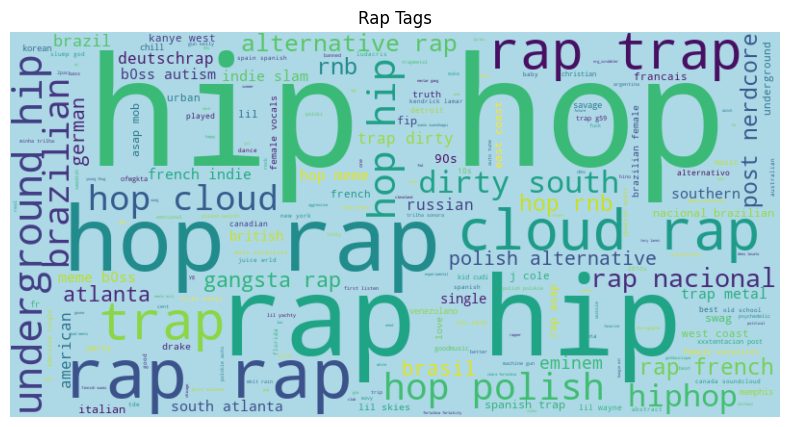

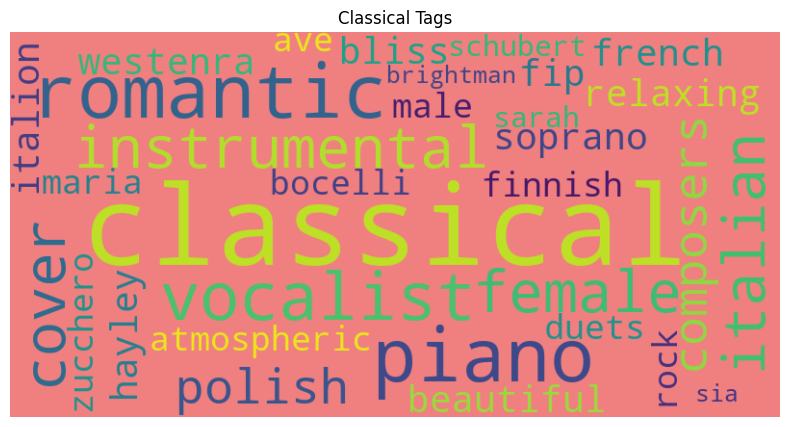

In [105]:
# Creating wordclouds for rap and rock genres
create_wordcloud(rap_tags, 'Rap Tags', color='lightblue')
create_wordcloud(classical_tags, 'Classical Tags', color='lightcoral')


### **Bar Chart**

Present the 10 most appeared tags grouped by the genre of the songs

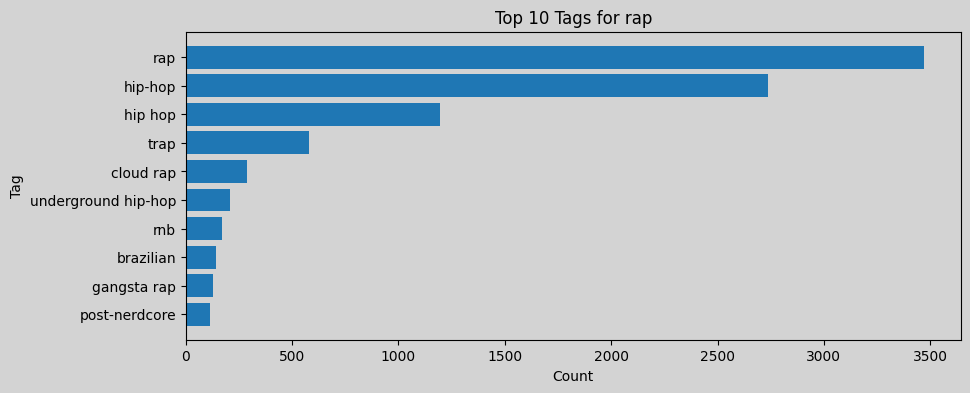

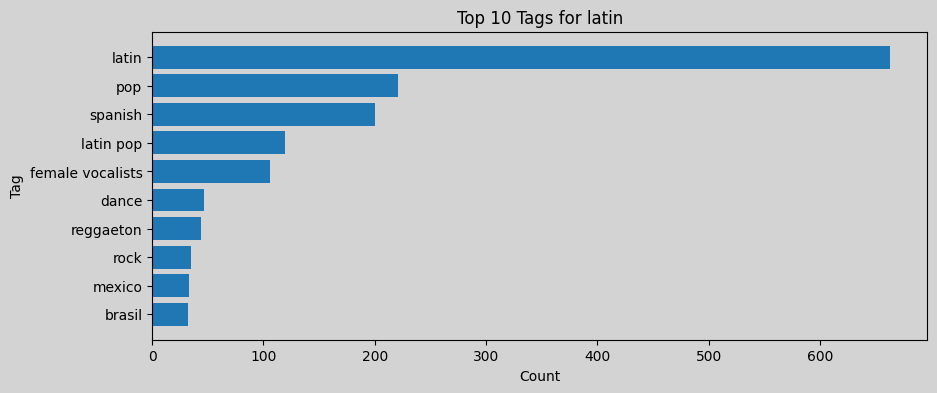

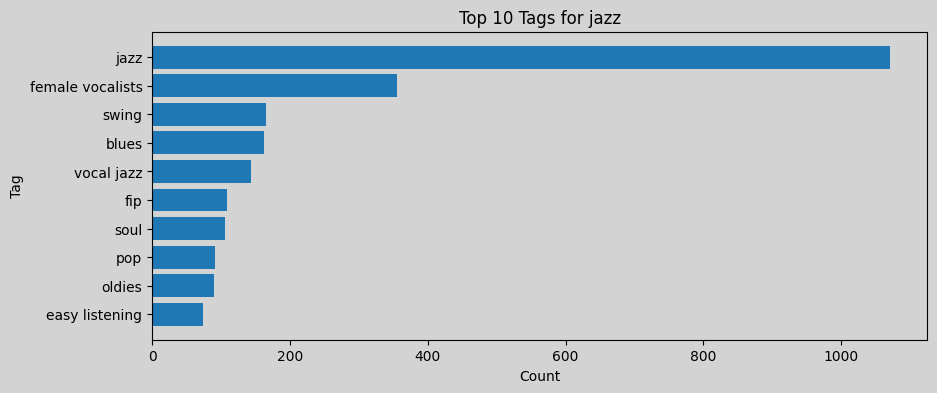

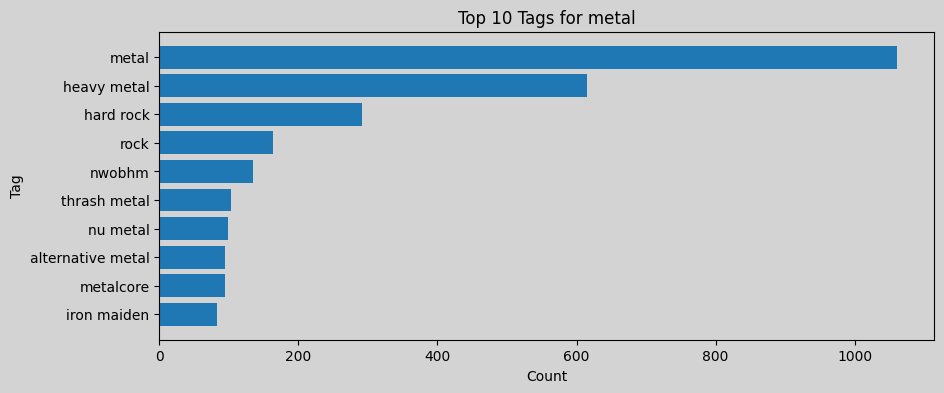

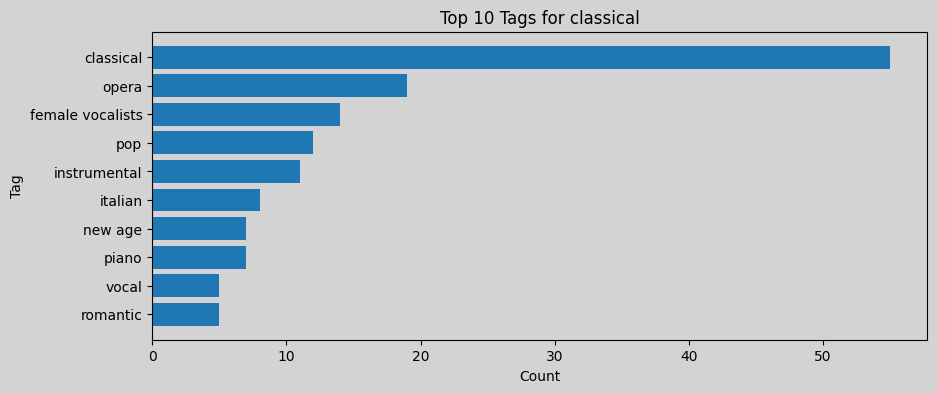

In [106]:
from collections import Counter
import matplotlib.pyplot as plt

data['tags_list'] = data['tags'].fillna('').apply(
    lambda x: [tag.strip() for tag in x.split(',') if tag.strip() != '']
)

for genre in data['main_genre'].unique():
    subset = data[data['main_genre'] == genre]

    all_tags = [tag for tags in subset['tags_list'] for tag in tags]

    tag_counts = Counter(all_tags)
    top_tags = tag_counts.most_common(10)

    tags, counts = zip(*top_tags)

    plt.figure(figsize=(10, 4)).patch.set_facecolor('lightgray')
    plt.barh(tags, counts)
    plt.gca().invert_yaxis()
    plt.gca().set_facecolor('lightgray')
    plt.title(f"Top 10 Tags for {genre}")
    plt.xlabel("Count")
    plt.ylabel("Tag")
    plt.show()

### **Dimensionality Reduction**

**Scatter Plot**  
We introduce the following function to help us compare the scatter plots between embedding generated on different bases.

In [107]:
from sklearn.manifold import TSNE

def scatter_plot_comparison(embed1, embed2, title1="PCA Embeddings", title2="Autoencoder Embeddings", data=data):

    # --- t-SNE visualization of the PCA and autoencoder embeddings ---
    tsne = TSNE(n_components=2, learning_rate=200, perplexity=50, max_iter=2000, random_state=42)
    X1 = tsne.fit_transform(embed1)
    X2 = tsne.fit_transform(embed2)

    # --- color the points by genre ---
    categories = data['main_genre'].astype('category')
    y = categories.cat.codes
    genre_names = categories.cat.categories

    # --- scatter plot of the t-SNE embeddings colored by genre ---
    fig, axes = plt.subplots(1,2, figsize=(12,6))

    scatter1 = axes[0].scatter(X1[:,0], X1[:,1], c=y, cmap='tab10', s=5)
    axes[0].set_title(title1)

    scatter2 = axes[1].scatter(X2[:,0], X2[:,1], c=y, cmap='tab10', s=5)
    axes[1].set_title(title2)

    handles, _ = scatter1.legend_elements()
    axes[1].legend(handles, genre_names, title="Genre", bbox_to_anchor=(1.05, 1), loc='upper left')

    plt.tight_layout()

    plt.show()




**Comparison between PCA and Autoencoder**

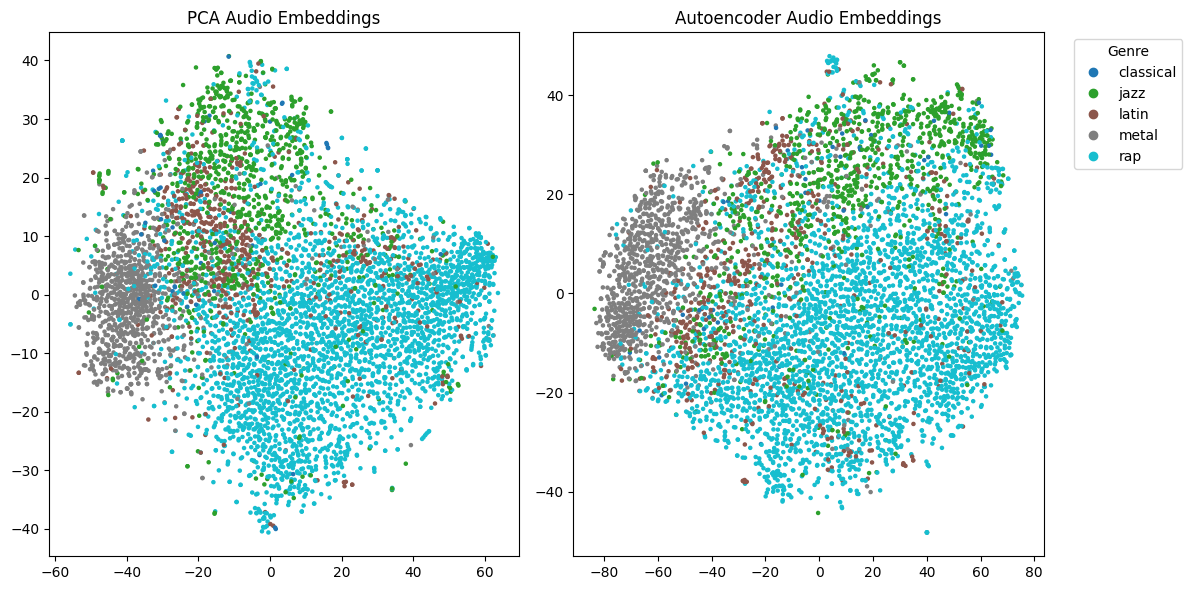

In [108]:
# --- Comparing the PCA and autoencoder embeddings with t-SNE visualization ---
scatter_plot_comparison(pca_audio_embeddings, autoenc_audio_embeddings, title1="PCA Audio Embeddings", title2="Autoencoder Audio Embeddings")

From the visualization of the audio embeddings (both PCA and Autoencoder-based), we can deduct that there is some patterns between the different genres. As we can see `metal` and `rap` have seemingly form distinctive clusters, while `latin` and `jazz` present also a similar pattern but they overlap with each other. `Classical` music has no clear pattern but also the sample we have is comparatively small.
In the next part, we will introduce classifiers to better capture the underlying structure of the data and improve genre discrimination.

**Comparison between Audio and Text Embeddings**

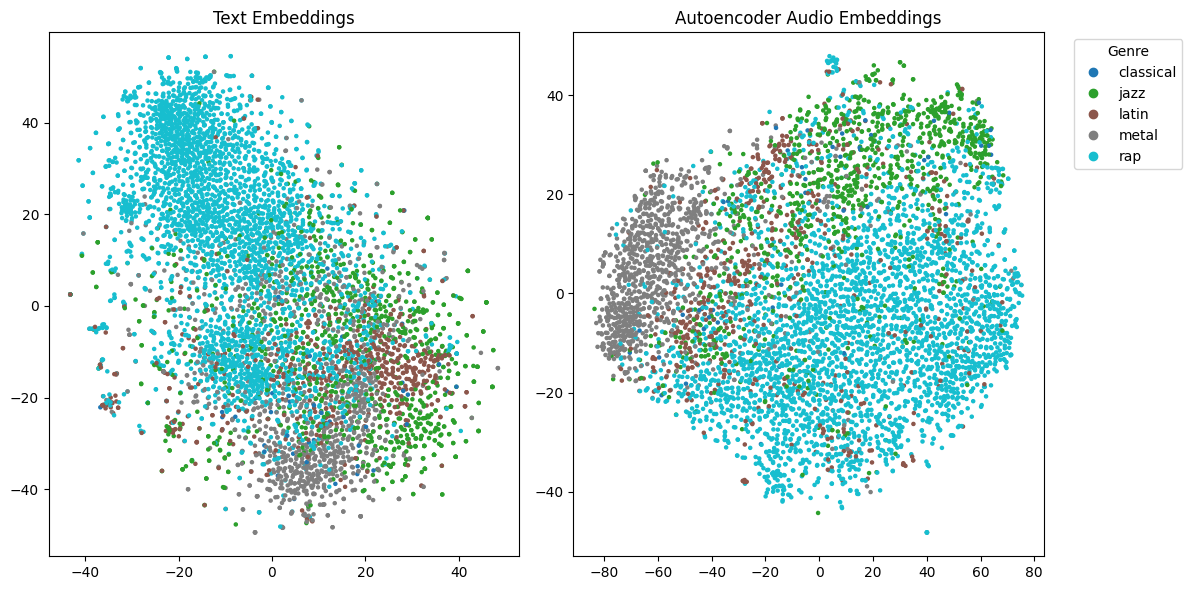

In [110]:
scatter_plot_comparison(embed1=text_embeddings_matrix, embed2=autoenc_audio_embeddings, title1="Text Embeddings", title2="Autoencoder Audio Embeddings")

### **Cosine Similarity**

In [140]:
from sklearn.metrics.pairwise import cosine_similarity

def top_n_similar_songs(song_pos, data, embeddings=autoenc_audio_embeddings, n=5):
    X = embeddings
    similarity_matrix = cosine_similarity(X)
    similarity_df = pd.DataFrame(similarity_matrix, index=data['id'], columns=data['id'])
    song_id = data['id'].iloc[song_pos]      
    similar_songs = similarity_df.loc[song_id].sort_values(ascending=False)[1:n+1]
    similar_songs_ids = similar_songs.index.tolist()
    similar_songs_names = data[data['id'].isin(similar_songs_ids)][["song","genres","main_genre"]]
    return similar_songs_names



**Cosine similarity: PCA vs Autoencoder**  


In [141]:
# --- Example: top 5 similar songs to i-th song in the dataset using audio embeddings ---
song_position = 1
top_5_similar_songs_enc = top_n_similar_songs(song_pos=song_position, data=data, embeddings=autoenc_audio_embeddings, n=5)
print("Top 5 similar songs to the " + data['genres'].iloc[song_position] + " song '" + data['song'].iloc[song_position] + "' (Autoencoder):")
print(top_5_similar_songs_enc)

top_5_similar_songs_pca = top_n_similar_songs(song_pos=song_position, data=data, embeddings=pca_audio_embeddings, n=5)
print("Top 5 similar songs to the " + data['genres'].iloc[song_position] + " song '" + data['song'].iloc[song_position] + "' (PCA):")
print(top_5_similar_songs_pca)

Top 5 similar songs to the rap song 'Duro Igual Concreto' (Autoencoder):
                     song                        genres main_genre
365                Colors                           rap        rap
1480               MERLOT       rap,hip hop,rap,hip hop        rap
2156  Higher (King Pt. 6)  rap,southern hip hop,hip hop        rap
5176           Goosebumps                       rap,rap        rap
5384             Rich $ex                           rap        rap
Top 5 similar songs to the rap song 'Duro Igual Concreto' (PCA):
                 song               genres main_genre
1462     South Dakota          rap,hip hop        rap
2322  Cambiare Adesso                  rap        rap
3391        Part Ways  rap,drill,rap,drill        rap
5516              M'$          rap,hip hop        rap
5979            No No                  rap        rap



After experimenting on the cosine similarity of the songs and extracting the top-5 similar songs of a variety of songs using the PCA embeddings and the autoencoder embeddings, we notice that similarity results differ between PCA-based and Autoencoder-based embeddings, indicating that each method captures different aspects of the audio data.  
PCA is a linear dimensionality reduction technique that is based on the variance. As a result, it tends to capture more global and general characteristics of the songs and brings close songs with similar high-level structure.  
The Autoencoder, as a non-linear model, learns more complex similarity patterns between the songs and possibly can capture more deep relationships between the MFCC stats.  
Different embedding methods emphasize different properties of the data, leading to different nearest-neighbor relationships between songs.


**Cosine Similarity: Audio Embeddings vs Text Embeddings**

In [142]:
# --- Top 5 similar songs: Comparison between text and audio embeddings ---
song_position = 1
top_5_similar_songs_enc = top_n_similar_songs(song_pos=song_position, data=data, embeddings=autoenc_audio_embeddings, n=5)
print("Top 5 similar songs to the " + data['genres'].iloc[song_position] + " song '" + data['song'].iloc[song_position] + "' (Autoencoder):")
print(top_5_similar_songs_enc)

top_5_similar_songs_pca = top_n_similar_songs(song_pos=song_position, data=data, embeddings=pca_audio_embeddings, n=5)
print("Top 5 similar songs to the " + data['genres'].iloc[song_position] + " song '" + data['song'].iloc[song_position] + "' (PCA):")
print(top_5_similar_songs_pca)

top_n_similar_songs_text = top_n_similar_songs(song_pos=song_position, data=data, embeddings=text_embeddings_matrix, n=5)
print("Top 5 similar songs to the " + data['genres'].iloc[song_position] + " song '" + data['song'].iloc[song_position] + "' (Text):")
print(top_n_similar_songs_text)

Top 5 similar songs to the rap song 'Duro Igual Concreto' (Autoencoder):
                     song                        genres main_genre
365                Colors                           rap        rap
1480               MERLOT       rap,hip hop,rap,hip hop        rap
2156  Higher (King Pt. 6)  rap,southern hip hop,hip hop        rap
5176           Goosebumps                       rap,rap        rap
5384             Rich $ex                           rap        rap
Top 5 similar songs to the rap song 'Duro Igual Concreto' (PCA):
                 song               genres main_genre
1462     South Dakota          rap,hip hop        rap
2322  Cambiare Adesso                  rap        rap
3391        Part Ways  rap,drill,rap,drill        rap
5516              M'$          rap,hip hop        rap
5979            No No                  rap        rap
Top 5 similar songs to the rap song 'Duro Igual Concreto' (Text):
                song                   genres main_genre
530          

***Comparison of the different Embeddings***

In [146]:
'''
Function to calculate the recall@n of the nearest neighbors
that actually belong to the same 'genre' like the query.

Purpose of the function is to analyse which embeddings( Audio(PCA and Autoencoder) or Text )
are bringing "closer" data of the same genre.
'''
def recall_of_same_genre(data, num_of_data, embeddings=autoenc_audio_embeddings):
    total_recall = 0
    num_of_data = 200
    n = 10
    for i in range(num_of_data):
        song_genre = data["main_genre"].iloc[i]
        top_similar_songs_enc = top_n_similar_songs(song_pos=i, data=data, embeddings=embeddings, n=n)
        same = 0
        for genre in top_similar_songs_enc["main_genre"].to_list():
            if genre==song_genre:
                same += 1

        total_recall += (same / n)

    return total_recall / num_of_data


In [147]:
embed_types = ["Autoencoder", "PCA", "TEXT"]
results = [
    recall_of_same_genre(data, 100, embeddings=autoenc_audio_embeddings),
    recall_of_same_genre(data, 100, embeddings=pca_audio_embeddings),
    recall_of_same_genre(data, 100, embeddings=text_embeddings_matrix),
    ]

header = " | ".join([f"{name:^15}" for name in embed_types])
separator = "-"*len(header)
values = " | ".join([f"{val:^15.4f}" for val in results])

print(separator)
print(header)
print(separator)
print(values)
print(separator)

---------------------------------------------------
  Autoencoder   |       PCA       |      TEXT      
---------------------------------------------------
    0.6890      |     0.7150      |     0.6600     
---------------------------------------------------
